# K-Means Image Segmentation

This notebook demonstrates how K-Means clustering groups pixels by similar RGB colors. It includes the original and segmented images, the elbow method, repeated runs, and a second flower-image example.

**To run from scratch:** keep `ladybug.jpg` in the same folder as this notebook. The flower image is loaded from scikit-learn.

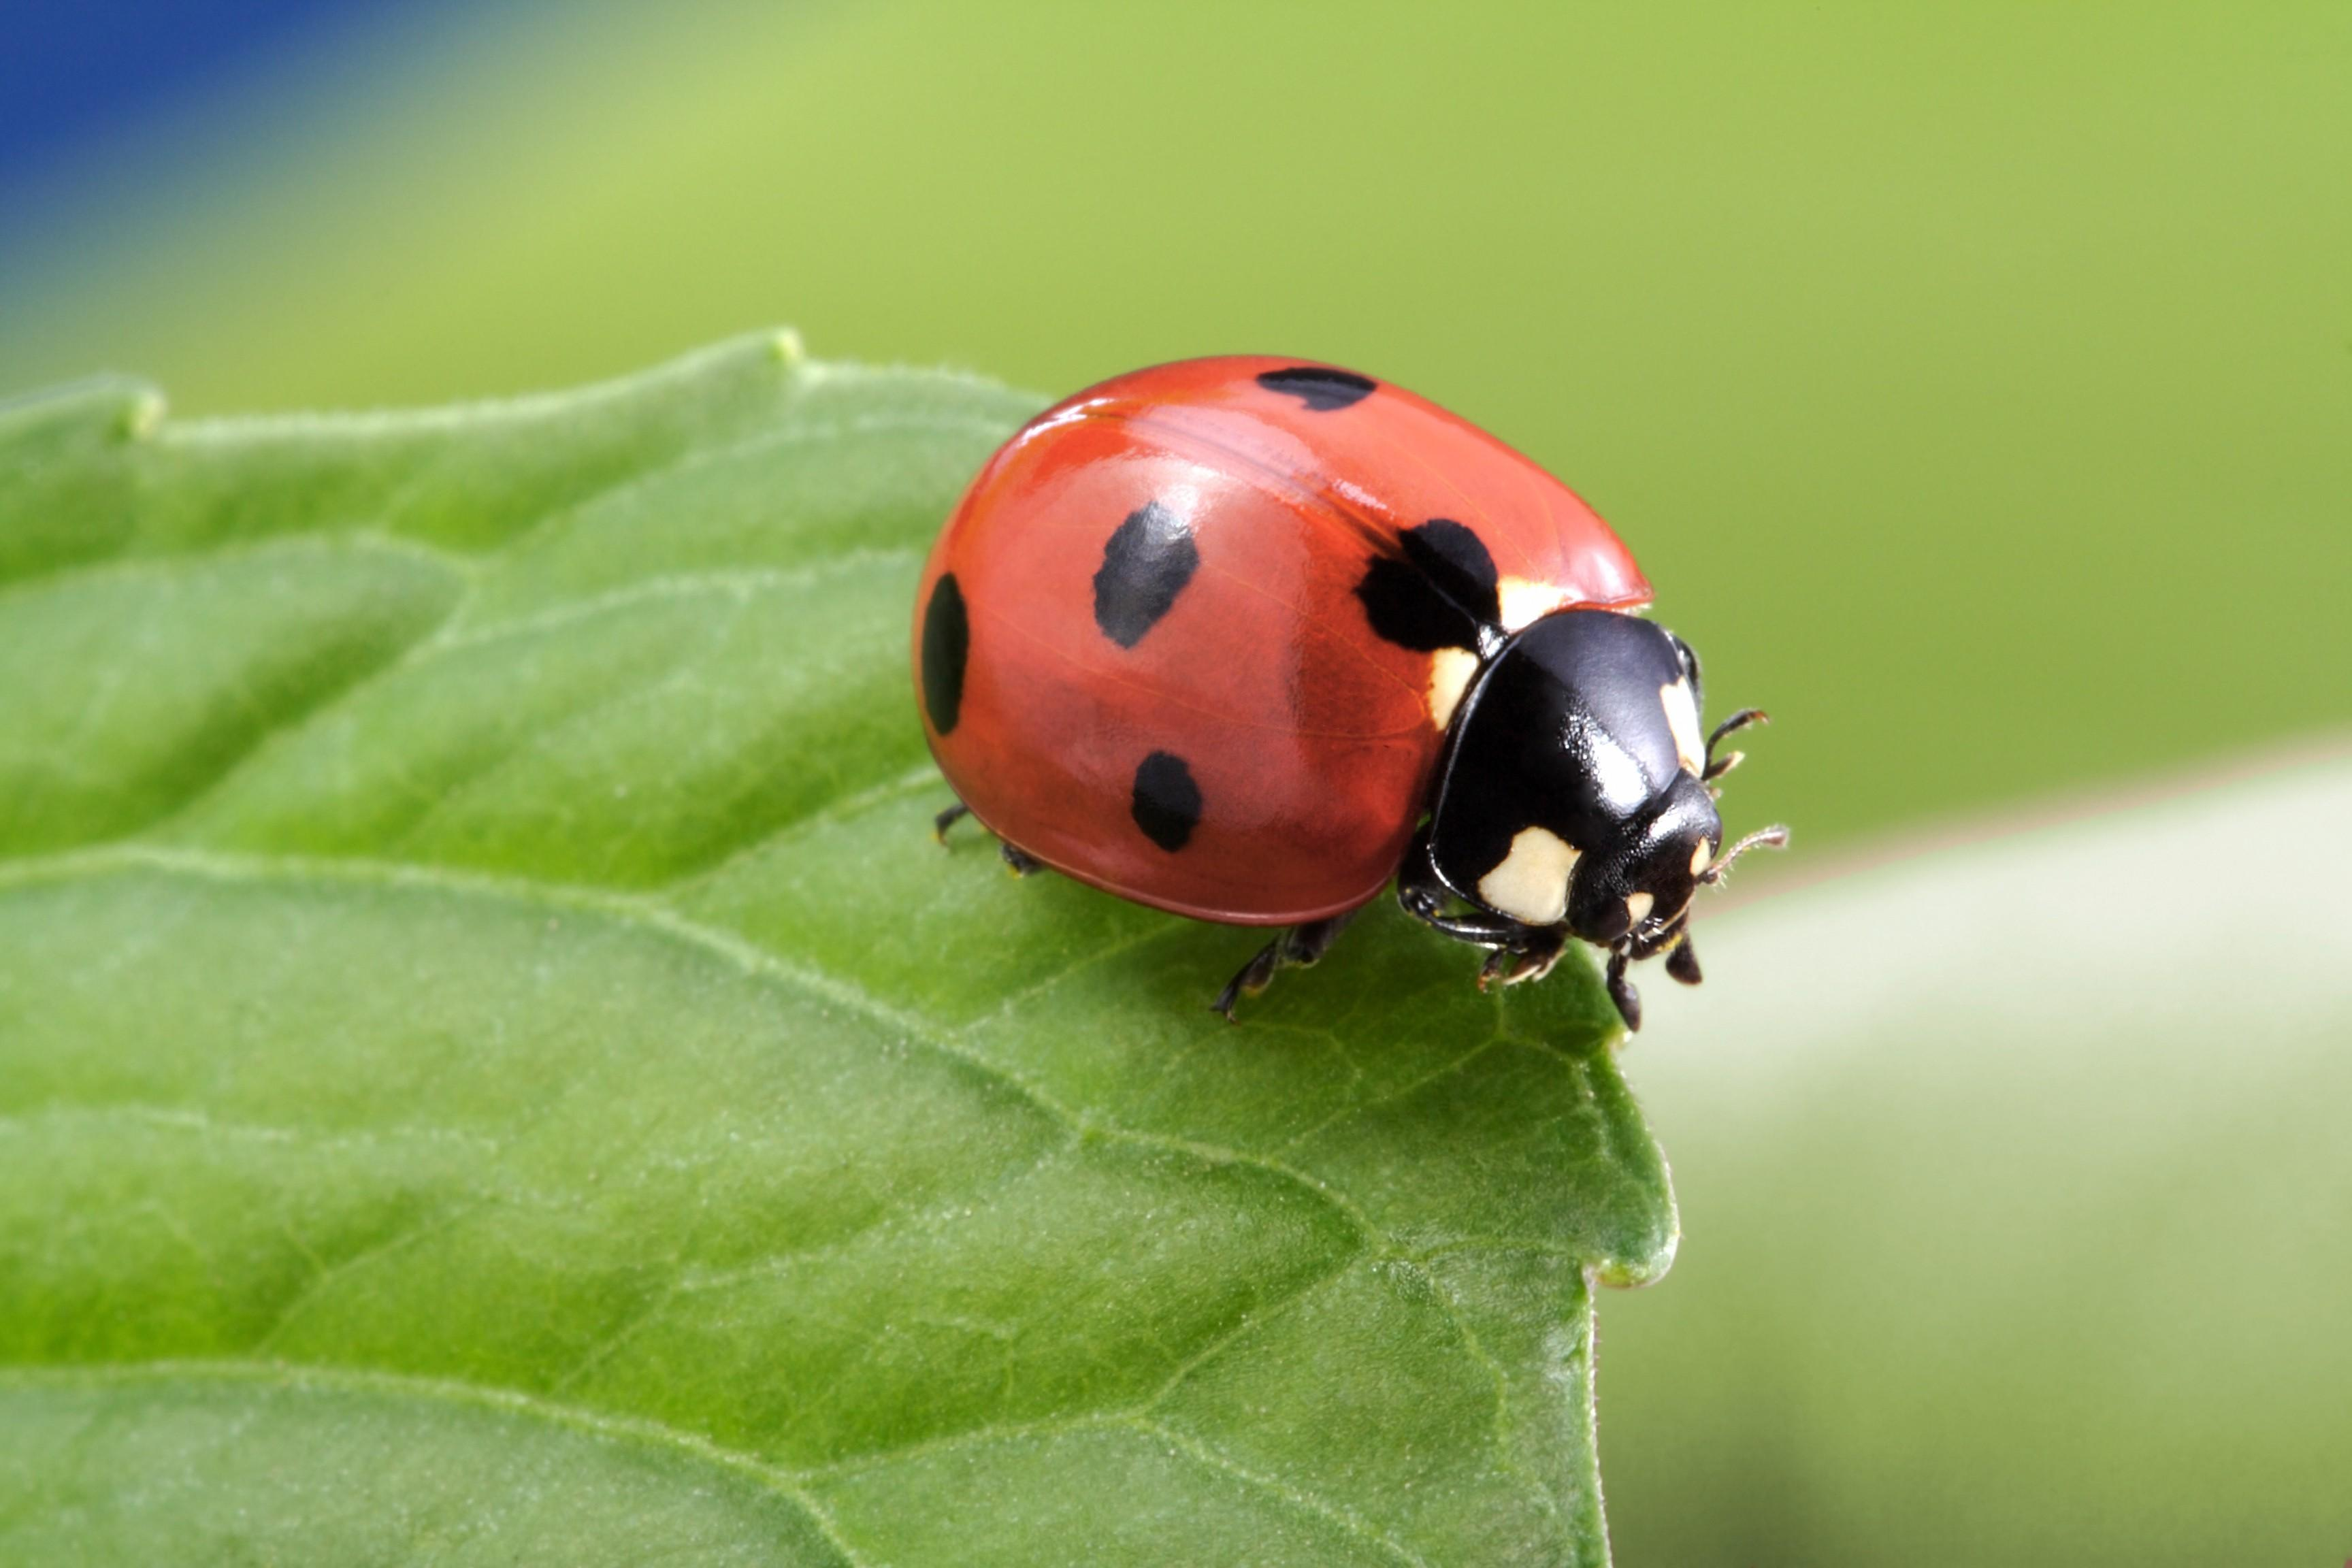

In [1]:
import PIL
from PIL import Image
import numpy as np

image = PIL.Image.open('./ladybug.jpg')

display(image)

In [2]:
# Convert the image into a NumPy array

X = np.asarray(image)

# Display the shape of the array

print(X.shape)

(2304, 3456, 3)


In [3]:
# Downsample every 4th pixel
X = X[::4, ::4, :]

# Display the new shape
print(X.shape)

# Save the image dimensions
shp = X.shape

(576, 864, 3)


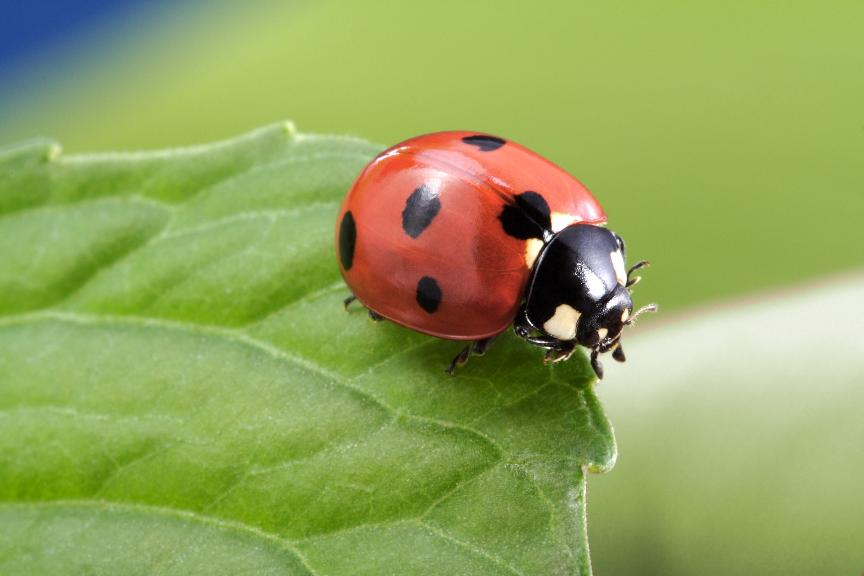

In [4]:
# Display the downsampled image
display(Image.fromarray(X))

In [6]:
# Convert the image into a 2D array
X = X.reshape(-1, 3)

# Display the new shape
print(X.shape)

(497664, 3)


In [7]:
from sklearn.cluster import KMeans

# Create a K-Means model with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=1)

# Train the model using our pixel data
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 3)","[[

In [8]:
# Replace each pixel with its cluster center color
segmented_img = kmeans.cluster_centers_[kmeans.labels_]

# Display the shape
print(segmented_img.shape)

(497664, 3)


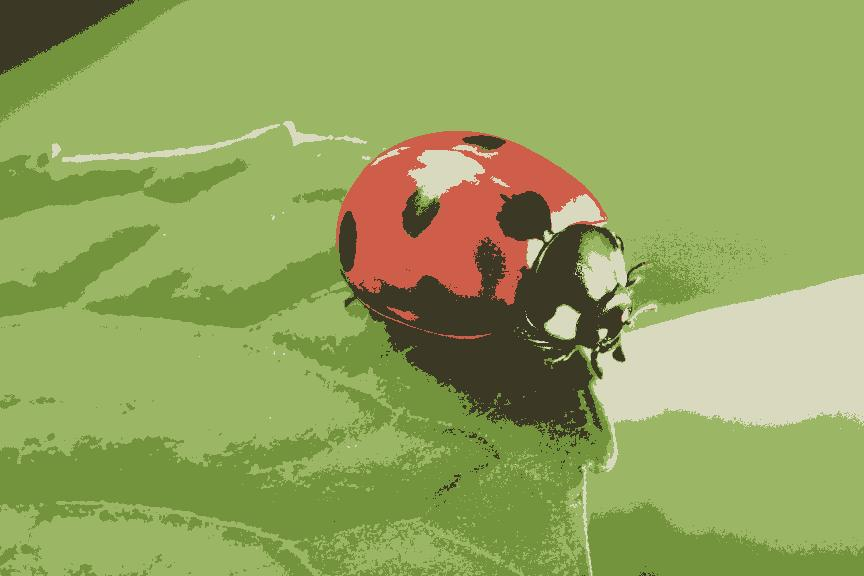

In [9]:
# Reshape the data back to the original image dimensions
segmented_img = segmented_img.reshape(shp)

# Convert pixel values to integers
segmented_img = segmented_img.astype(np.uint8)

# Display the segmented image
display(Image.fromarray(segmented_img))

In [10]:
print("K-Means Inertia:", kmeans.inertia_)

K-Means Inertia: 588422570.4916531


In [11]:
import matplotlib.pyplot as plt

# Store inertia values for different K values
inertias = []

# Try K-Means with 1 to 20 clusters
for k in range(1, 21):
    kmeans_temp = KMeans(n_clusters=k, random_state=1)
    kmeans_temp.fit(X)

    # Store the inertia for this K
    inertias.append(kmeans_temp.inertia_)

print(inertias)

[2680595463.9973373, 1515855067.3140435, 1003844975.391696, 840647726.9344201, 588422570.4916531, 501406296.34429514, 383387862.84786624, 343121843.06175435, 304858141.79570055, 282239076.67005944, 225393444.4368288, 201308306.97698992, 186795039.6060329, 169180389.64332163, 158193251.08966804, 151621010.18699044, 139219644.9057427, 133255572.18092088, 123212445.11819257, 117731743.24902076]


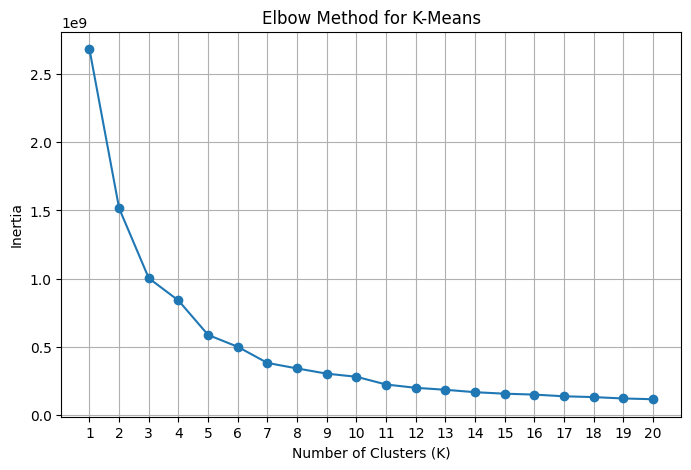

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 21), inertias, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(range(1, 21))
plt.grid(True)

plt.show()

In [13]:
inertia_scores = []

for i in range(10):
    kmeans = KMeans(n_clusters=5, random_state=i)
    kmeans.fit(X)

    inertia_scores.append(kmeans.inertia_)

print(inertia_scores)

[588409246.5730784, 588422570.4916532, 588407150.4159719, 638902932.7034862, 676667390.9764922, 588408524.4353999, 588408130.1876853, 588413596.5292938, 588412946.8968823, 660334171.7472662]


In [14]:
import numpy as np

mean_inertia = np.mean(inertia_scores)
std_inertia = np.std(inertia_scores)
min_inertia = np.min(inertia_scores)
max_inertia = np.max(inertia_scores)

print("Mean Inertia:", mean_inertia)
print("Standard Deviation:", std_inertia)
print("Minimum Inertia (Best):", min_inertia)
print("Maximum Inertia (Worst):", max_inertia)

Mean Inertia: 609478666.0957209
Standard Deviation: 33276272.447457787
Minimum Inertia (Best): 588407150.4159719
Maximum Inertia (Worst): 676667390.9764922


In [15]:
kmeans_models = []

for i in range(10):
    model = KMeans(n_clusters=5, random_state=i)
    model.fit(X)
    kmeans_models.append(model)

best_index = np.argmin([model.inertia_ for model in kmeans_models])
worst_index = np.argmax([model.inertia_ for model in kmeans_models])

print("Best run:", best_index + 1)
print("Worst run:", worst_index + 1)

Best run: 3
Worst run: 5


In [16]:
# Get the best and worst K-Means models
best_model = kmeans_models[best_index]
worst_model = kmeans_models[worst_index]

# Reconstruct the best segmented image
best_segmented = best_model.cluster_centers_[best_model.labels_]
best_segmented = best_segmented.reshape(shp).astype(np.uint8)

# Reconstruct the worst segmented image
worst_segmented = worst_model.cluster_centers_[worst_model.labels_]
worst_segmented = worst_segmented.reshape(shp).astype(np.uint8)

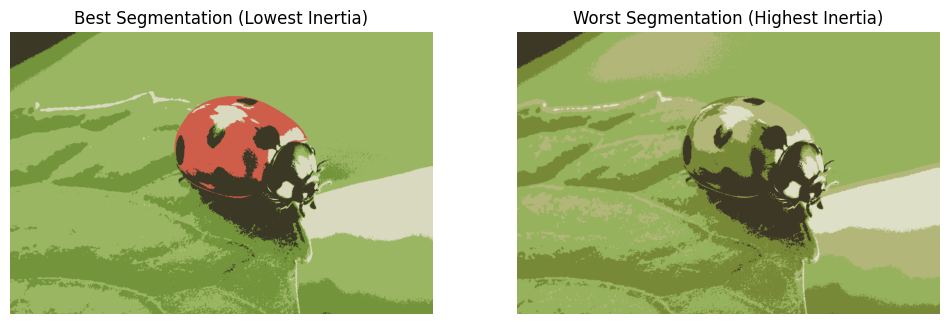

In [17]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(best_segmented)
plt.title("Best Segmentation (Lowest Inertia)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(worst_segmented)
plt.title("Worst Segmentation (Highest Inertia)")
plt.axis("off")

plt.show()

In [18]:
mean_inertias = []
min_inertias = []
max_inertias = []

for k in range(1, 21):
    scores = []

    for i in range(10):
        model = KMeans(n_clusters=k, random_state=i)
        model.fit(X)
        scores.append(model.inertia_)

    mean_inertias.append(np.mean(scores))
    min_inertias.append(np.min(scores))
    max_inertias.append(np.max(scores))

print("Completed!")

Completed!


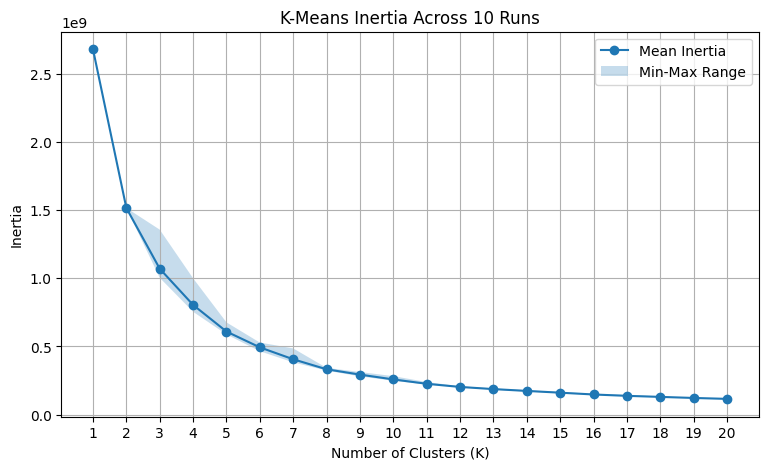

In [19]:
k_values = range(1, 21)

plt.figure(figsize=(9, 5))

plt.plot(k_values, mean_inertias, marker='o', label='Mean Inertia')
plt.fill_between(k_values, min_inertias, max_inertias,
                 alpha=0.25, label='Min-Max Range')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Inertia Across 10 Runs")
plt.xticks(range(1, 21))
plt.legend()
plt.grid(True)
plt.show()


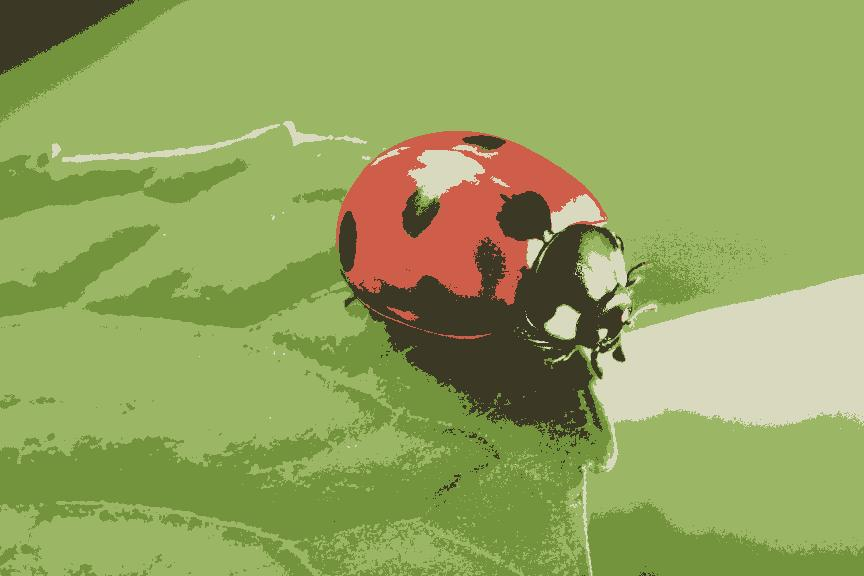

In [20]:
kmeans_q3 = KMeans(n_clusters=5, random_state=1)
kmeans_q3.fit(X)

segmented_q3 = kmeans_q3.cluster_centers_[kmeans_q3.labels_]
segmented_q3 = segmented_q3.reshape(shp).astype(np.uint8)

display(Image.fromarray(segmented_q3))

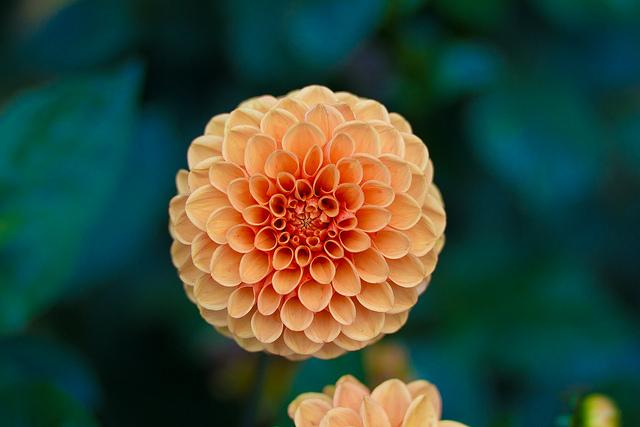

In [21]:
from sklearn.datasets import load_sample_image

flower = load_sample_image("flower.jpg")

display(Image.fromarray(flower))

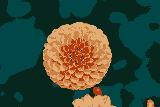

In [22]:
# Convert image to NumPy array
flower_X = np.asarray(flower)

# Downsample the image
flower_X = flower_X[::4, ::4, :]

# Save image dimensions
flower_shape = flower_X.shape

# Reshape into rows of RGB pixels
flower_X = flower_X.reshape(-1, 3)

# Apply K-Means
flower_kmeans = KMeans(n_clusters=5, random_state=1)
flower_kmeans.fit(flower_X)

# Reconstruct segmented image
flower_segmented = flower_kmeans.cluster_centers_[flower_kmeans.labels_]
flower_segmented = flower_segmented.reshape(flower_shape).astype(np.uint8)

# Display result
display(Image.fromarray(flower_segmented))